# From correlation to angular distance

This Julia notebook follows the same experiment, equations, sample sizes, parameters, and decision rules as its Python counterpart. Random experiments use the displayed integer seeds with Julia’s `Xoshiro` generator, so their realized samples differ from NumPy. Public observations use the same stated data sources. Figures use the requested dark theme, and Julia outputs are saved under `outputs/julia`. Nearest-neighbor tie-breaking jitter also uses saved Xoshiro draws. All simulated inputs and encoded messages are retained so the calculations can be repeated across languages.

The first distance treats negative correlation as far apart, while the second treats equal positive and negative correlations as equally close:

$$
d_{\rho}(X,Y)=\sqrt{\frac{1-\rho(X,Y)}{2}},
\qquad
d_{|\rho|}(X,Y)=\sqrt{\frac{1-|\rho(X,Y)|}{2}}.
$$

Here, $X$ and $Y$ are paired return series; $\rho(X,Y)\in[-1,1]$ is their sample correlation. $d_{\rho}$ is angular distance; $d_{|\rho|}$ is distance based on absolute correlation; $|\cdot|$ is absolute value.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("09_dependence_geometry_information");
using CSV, Printf
using RiskLabAI.Data: calculate_distance,calculate_mutual_information,calculate_number_of_bins,calculate_variation_of_information,calculate_variation_of_information_extended,distance_correlation,ksg_mutual_information
using RiskLabAI.Features: shannon_entropy,probability_mass_function,plug_in_entropy_estimator,lempel_ziv_entropy,kontoyiannis_entropy,miller_madow_entropy,grassberger_entropy,nsb_entropy
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
minute_close = raw.close
resampled = combine(groupby(DataFrame(time=floor.(raw.time,Minute(15)),price=raw.close),:time;sort=true),:price=>last=>:close)
close_index,close_prices = resampled.time,resampled.close
log_price = log.(close_prices)
return_values,return_index = diff(log_price),close_index[2:end]
violet = "#C084FC"

function contingency_counts(x,y,bins)
    xedges,yedges = collect(range(extrema(x)...;length=bins+1)),collect(range(extrema(y)...;length=bins+1))
    counts = zeros(Int,bins,bins)
    for (left,right) in zip(x,y)
        counts[min(searchsortedlast(xedges,left),bins),min(searchsortedlast(yedges,right),bins)] += 1
    end
    return counts
end

function histogram_information(counts)
    probability = counts./sum(counts)
    marginal_x,marginal_y = vec(sum(probability;dims=2)),vec(sum(probability;dims=1))
    entropy(values) = -sum(value*log(value) for value in values if value>0)
    entropy_x,entropy_y,joint = entropy(marginal_x),entropy(marginal_y),entropy(probability)
    information = sum(probability[left,right]*log(probability[left,right]/(marginal_x[left]*marginal_y[right])) for left in axes(counts,1),right in axes(counts,2) if probability[left,right]>0)
    variation = entropy_x+entropy_y-2information
    return (information=information,joint=joint,variation=variation,normalized_mi=information/min(entropy_x,entropy_y),normalized_vi=variation/joint)
end


histogram_information (generic function with 1 method)

## Distances from Public Returns

In [2]:
data_provenance = DataFrame("Field"=>["Archive","Provider","Public access","Market","Minute records","Analysis interval","Analysis records","Return observations","First analysis time","Last analysis time"],"Value"=>["BTCUSDT-1m-2021-01.zip","Binance Data Vision","Direct public download","Bitcoin quoted in USDT",string(length(minute_close)),"Fifteen minutes",string(length(close_prices)),string(length(return_values)),string(first(close_index)),string(last(close_index))])
feature_names = ["One-interval return","Two-interval return","Four-interval return","Eight-interval return","Negative one-interval return"]
feature_matrix = hcat([log_price[9:end].-log_price[9-lag:end-lag] for lag in [1,2,4,8]]...,-(log_price[9:end].-log_price[8:end-1]))
feature_frame = DataFrame(feature_matrix,feature_names)
correlation = cor(feature_matrix)
angular = calculate_distance(correlation;metric="angular")
absolute_angular = calculate_distance(correlation;metric="absolute_angular")
pair_rows = NamedTuple[]
for left in 1:length(feature_names),right in left+1:length(feature_names)
    push!(pair_rows,(pair=feature_names[left]*" and "*feature_names[right],correlation=correlation[left,right],angular=angular[left,right],absolute=absolute_angular[left,right]))
end
correlation_distance_pairs = DataFrame(pair_rows)
rename!(correlation_distance_pairs,["Pair","Correlation","Angular distance","Absolute-correlation distance"])
save_table(data_provenance,paths,"data_provenance";caption="Public data used in Chapter 8.",label="tab:chapter8-data-provenance")
save_table(correlation_distance_pairs,paths,"correlation_distance_pairs";caption="Correlation and its two distance transformations for public return pairs.",label="tab:chapter8-correlation-distance-pairs")
save_data(hcat(DataFrame(time=close_index[9:end]),feature_frame),paths,"return_features")
save_data(DataFrame(time=return_index,return_value=return_values),paths,"public_returns");


11×2 DataFrame
 Row │ Field                Value
     │ String               String
─────┼────────────────────────────────────────────────────────
   1 │ Archive              BTCUSDT-1m-2021-01.zip
   2 │ Provider             Binance Data Vision
   3 │ Public access        Direct public download
   4 │ Market               Bitcoin quoted in USDT
   5 │ Minute records       44640
   6 │ Analysis interval    Fifteen minutes
   7 │ Analysis records     2976
   8 │ Return observations  2975
   9 │ First analysis time  2021-01-01T00:00:00
  10 │ Last analysis time   2021-01-31T23:45:00

Row,Pair,Correlation,Angular distance,Absolute-correlation distance
,String,Float64,Float64,Float64
1,One-interval return and Two-interval return,0.698595,0.388204,0.388204
2,One-interval return and Four-interval return,0.476032,0.511844,0.511844
3,One-interval return and Eight-interval return,0.324257,0.581267,0.581267
4,One-interval return and Negative one-interval return,-1.0,1.0,0.0
5,Two-interval return and Four-interval return,0.685822,0.396345,0.396345
6,Two-interval return and Eight-interval return,0.474392,0.512644,0.512644
7,Two-interval return and Negative one-interval return,-0.698595,0.921573,0.388204
8,Four-interval return and Eight-interval return,0.686467,0.395937,0.395937
9,Four-interval return and Negative one-interval return,-0.476032,0.859079,0.511844


## Euclidean Geometry

Angular distance is a scaled Euclidean distance between centered and standardized observations:

$$
z_{X,t}=\frac{X_t-\overline X}{s_X},
\qquad
d_{\rho}(X,Y)=\frac{\lVert z_X-z_Y\rVert_2}{2\sqrt{N}}.
$$

Here, $X_t$ is observation $t$; $\overline X$ is the sample mean; $s_X$ is the population-form sample standard deviation. $z_X$ and $z_Y$ are standardized vectors; $N$ is their common length; $\lVert\cdot\rVert_2$ is Euclidean length.

In [3]:
standardized = (feature_matrix.-mean(feature_matrix;dims=1))./std(feature_matrix;dims=1,corrected=false)
euclidean_scaled,sign_free_scaled = zeros(5,5),zeros(5,5)
for left in 1:5,right in 1:5
    x,y = standardized[:,left],standardized[:,right]
    euclidean_scaled[left,right] = norm(x-y)/(2sqrt(length(x)))
    sign_free_scaled[left,right] = min(norm(x-y),norm(x+y))/(2sqrt(length(x)))
end
metric_rows,matrix_rows = NamedTuple[],NamedTuple[]
for (label,matrix,geometric) in [("Angular distance",angular,euclidean_scaled),("Absolute-correlation distance",absolute_angular,sign_free_scaled)]
    triangle_excess = maximum(matrix[left,right]-matrix[left,middle]-matrix[middle,right] for left in 1:5,middle in 1:5,right in 1:5)
    push!(metric_rows,(distance=label,diagonal=maximum(abs.(diag(matrix))),symmetry=maximum(abs.(matrix.-transpose(matrix))),triangle=triangle_excess,geometry=maximum(abs.(matrix.-geometric))))
end
for left in 1:5,right in 1:5
    push!(matrix_rows,(left=left,right=right,correlation=correlation[left,right],angular=angular[left,right],absolute=absolute_angular[left,right],euclidean=euclidean_scaled[left,right],sign_free=sign_free_scaled[left,right]))
end
distance_metric_checks = DataFrame(metric_rows)
rename!(distance_metric_checks,["Distance","Largest diagonal value","Largest symmetry difference","Largest triangle excess","Largest geometric difference"])
save_table(distance_metric_checks,paths,"distance_metric_checks";caption="Numerical checks of distance properties and geometric identities.",label="tab:chapter8-distance-metric-checks")
save_data(DataFrame(matrix_rows),paths,"geometry_matrices")
save_data(DataFrame(standardized,feature_names),paths,"standardized_returns");


Row,Distance,Largest diagonal value,Largest symmetry difference,Largest triangle excess,Largest geometric difference
,String,Float64,Float64,Float64,Float64
1,Angular distance,0.0,0.0,0.0,3.21495e-7
2,Absolute-correlation distance,0.0,0.0,0.0,3.21495e-7


## Understanding the angular-distance scale

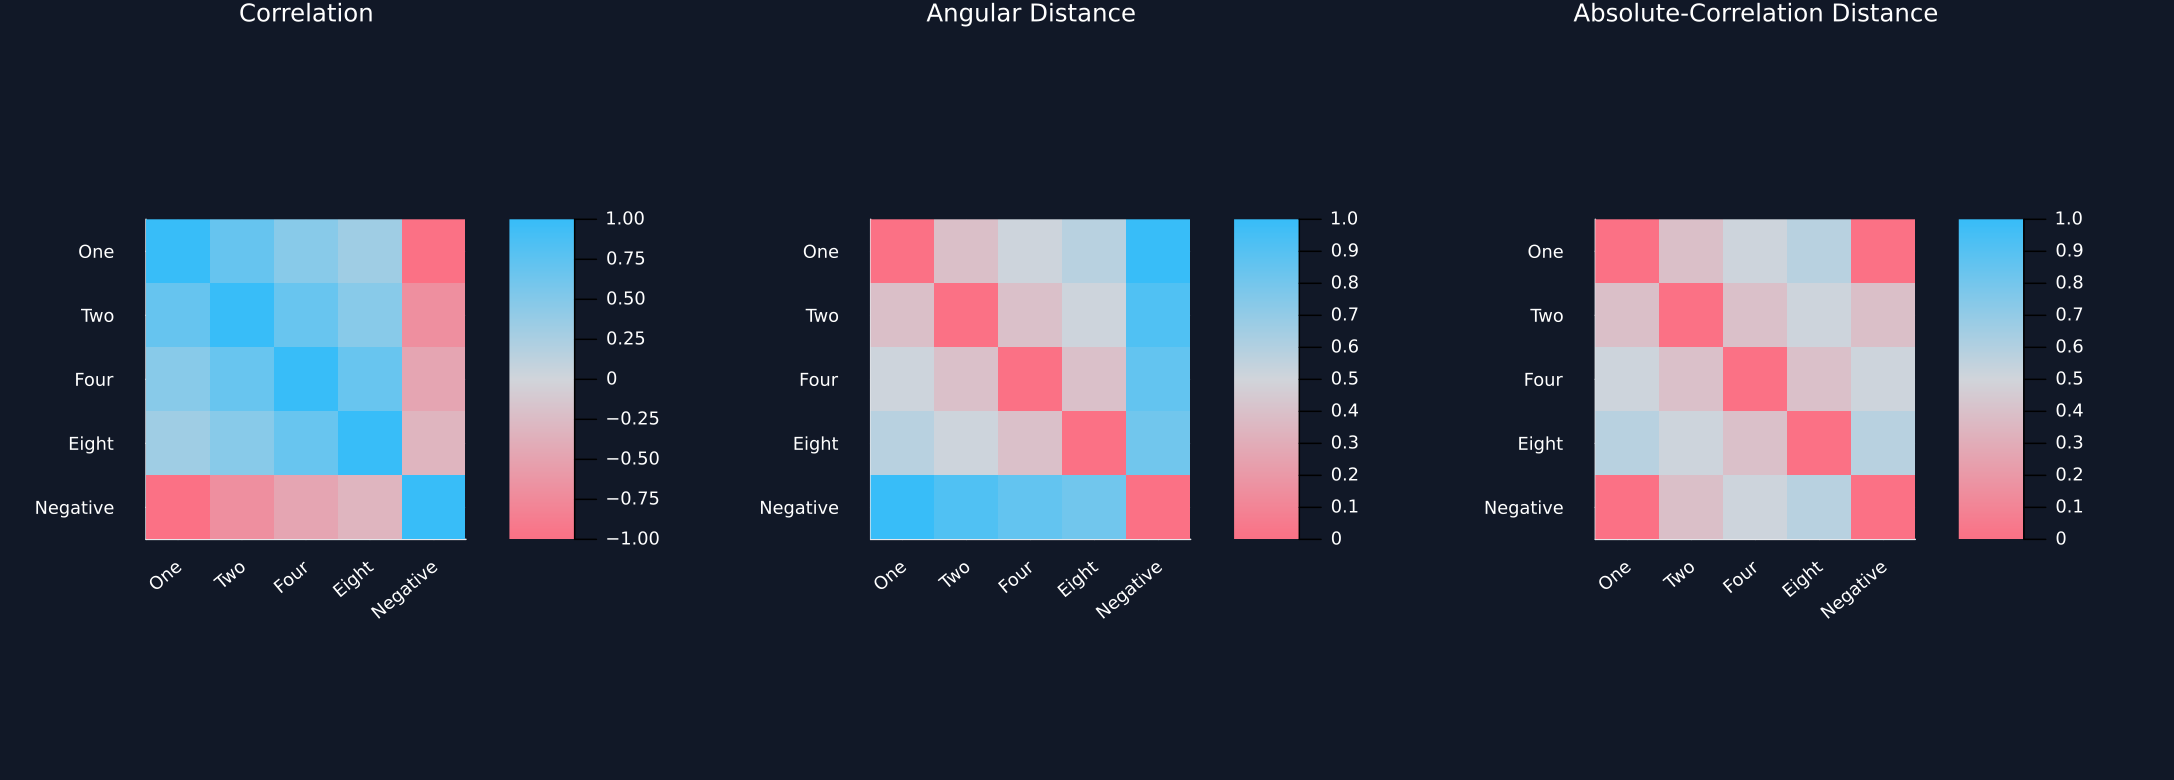

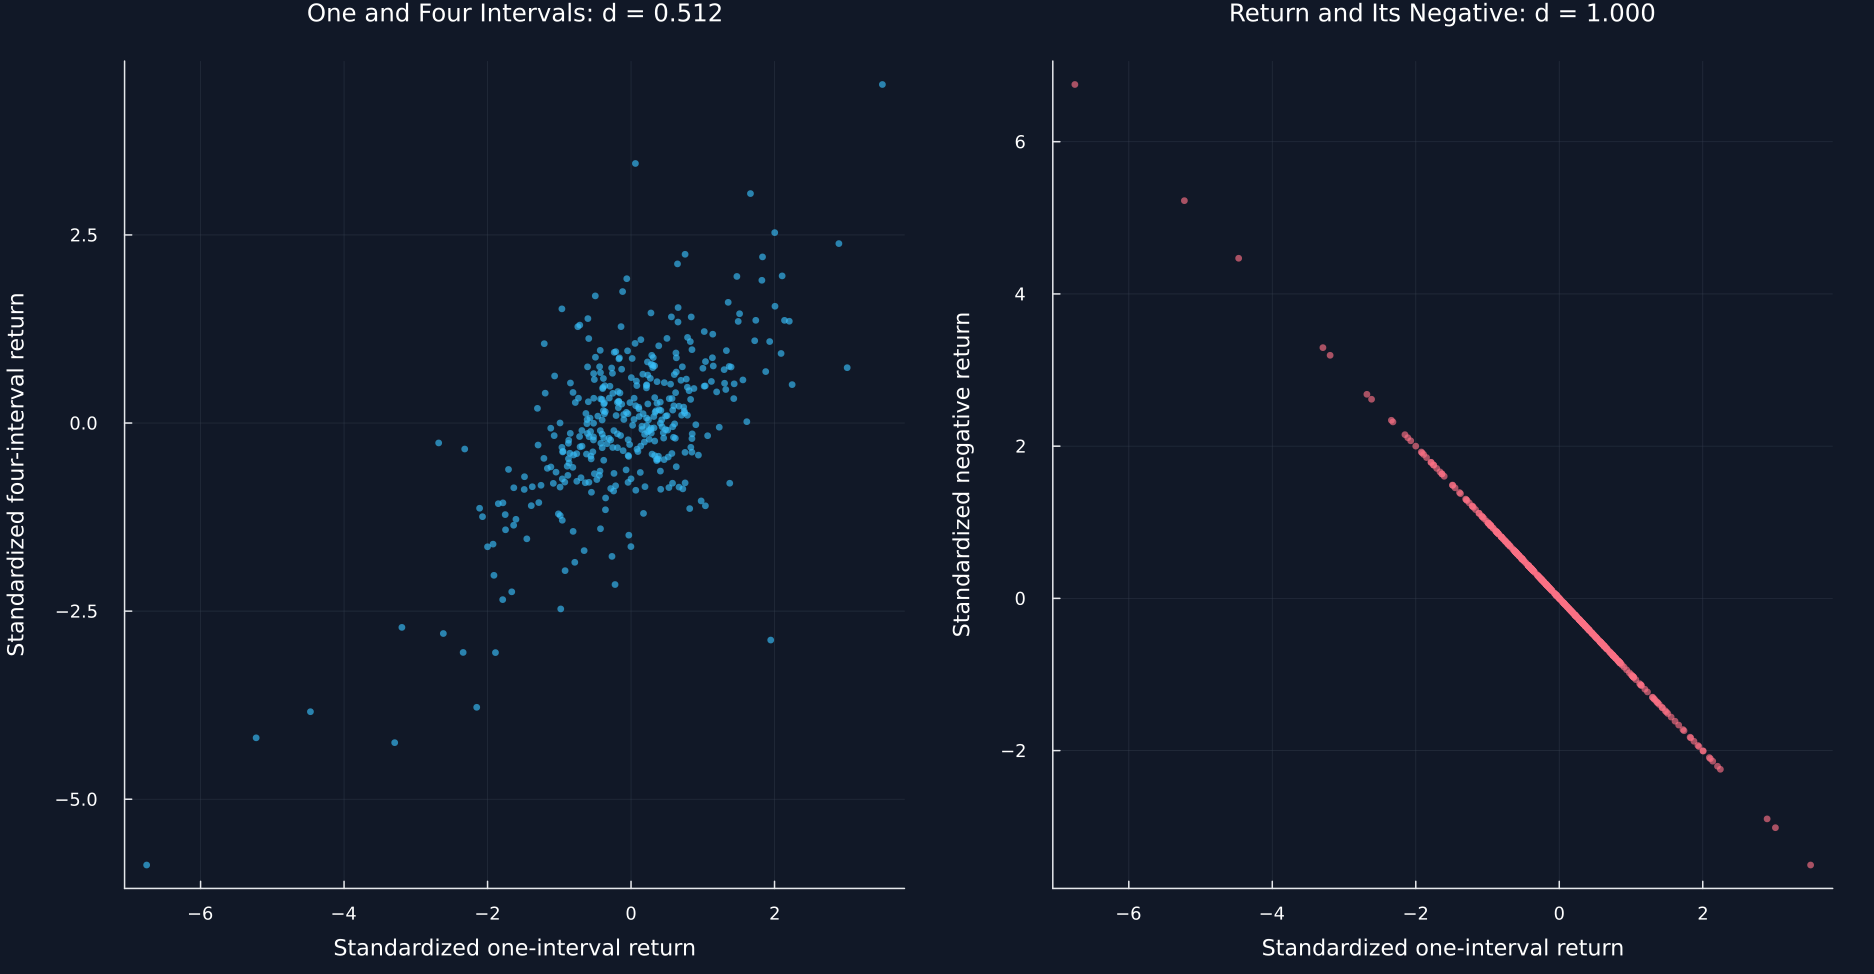

In [4]:
short_names = ["One","Two","Four","Eight","Negative"]
panels = []
for (matrix,title,limits) in [(correlation,"Correlation",(-1.,1.)),(angular,"Angular Distance",(0.,1.)),(absolute_angular,"Absolute-Correlation Distance",(0.,1.))]
    push!(panels,heatmap(1:5,1:5,matrix;color=cgrad([palette.rose,"#D1D5DB",palette.cyan]),clims=limits,xticks=(1:5,short_names),yticks=(1:5,short_names),xrotation=40,yflip=true,title,titlefontsize=11,aspect_ratio=:equal,xlims=(.5,5.5),ylims=(.5,5.5),widen=false))
end
save_figure(plot(panels...;layout=(1,3),size=(1450,520)),paths,"correlation_distance_matrices")
selected = 1:8:size(standardized,1)
p1 = scatter(standardized[selected,1],standardized[selected,3];color=palette.cyan,markersize=2.5,markerstrokewidth=0,alpha=.65,title=@sprintf("One and Four Intervals: d = %.3f",angular[1,3]),xlabel="Standardized one-interval return",ylabel="Standardized four-interval return",legend=false)
p2 = scatter(standardized[selected,1],standardized[selected,5];color=palette.rose,markersize=2.5,markerstrokewidth=0,alpha=.65,title=@sprintf("Return and Its Negative: d = %.3f",angular[1,5]),xlabel="Standardized one-interval return",ylabel="Standardized negative return",legend=false)
save_figure(plot(p1,p2;layout=(1,2),size=(1250,650)),paths,"standardized_geometry")


## Tests

In [5]:
@assert length(minute_close)==44640
@assert length(close_prices)==2976
@assert length(return_values)==2975
@assert nrow(feature_frame)==2968
@assert all(isapprox.(diag(correlation),1.))
@assert all(iszero,diag(angular))
@assert all(iszero,diag(absolute_angular))
@assert isapprox(angular,transpose(angular))
@assert isapprox(absolute_angular,transpose(absolute_angular))
@assert maximum(abs.(angular.-euclidean_scaled))<5e-7
@assert maximum(abs.(absolute_angular.-sign_free_scaled))<5e-7
@assert maximum(distance_metric_checks[!,"Largest triangle excess"])<1e-12
@assert isapprox(correlation[1,5],-1.)
@assert isapprox(angular[1,5],1.)
@assert iszero(absolute_angular[1,5])
@assert isfile(joinpath(paths.figures,"correlation_distance_matrices.pdf"))
@assert isfile(joinpath(paths.figures,"standardized_geometry.pdf"))
